# Lab 1 — Intro to Behavioral TV Data
Name: Ivan Morozov | Group: KM-43

## Setup

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")  # Colab and Kaggle
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

Some preparation for all tasks:
- broadcast day = time minus 6 hours
- persons = R and L (no guests)
- join attribute codes with their names, get sex and age for every person
- monthly weight = mean of daily weights of a person

In [2]:
import numpy as np

PERSON_TYPES = ["R", "L"]


def broadcast_day(ts):
    return (ts - pd.Timedelta(hours=6)).dt.normalize()


# weighted quantile, no interpolation
def weighted_quantile(values, weights, q):
    idx = np.argsort(values)
    v = np.asarray(values)[idx]
    w = np.asarray(weights, dtype=float)[idx]
    cum = np.cumsum(w) / w.sum()
    return v[np.searchsorted(cum, q)]


# codes -> names
attr = viewer_attributes.merge(attributes, on="attr_id", how="left")
print("Codes without a name:", attr.attr_name.isna().sum())
attr.head()

Codes without a name: 0


,respondent_id,attr_id,value,attr_group,attr_name,value_type,applies_to
0,10000100,104,NaN,Respondent type,H: household record (id ending 00),flag,"H,R,L,S"
1,10000100,802,NaN,Household size,2 persons,flag,H
2,10000100,815,NaN,Household income,$100k-$150k,flag,H
3,10000100,822,NaN,Children in household,No children under 18,flag,H
4,10000100,833,NaN,TV reception,Telco / fiber,flag,H


In [3]:
flags = attr[attr.value_type == "flag"].pivot_table(index="respondent_id", columns="attr_group",
                                                    values="attr_name", aggfunc="first")
age = attr[attr.attr_id == 300].set_index("respondent_id")["value"].rename("age")
people = flags.join(age)
people = people[people["Respondent type"].str[0].isin(PERSON_TYPES)].copy()
people["sex"] = people["Sex"].str[0]
people["age"] = people["age"].astype(int)


def age_group(a):
    if 18 <= a <= 34:
        return "18-34"
    if 35 <= a <= 54:
        return "35-54"
    if a >= 55:
        return "55+"
    return "2-17"


people["age_group"] = people["age"].map(age_group)
people["demo"] = people["sex"].map({"M": "M", "F": "W"}) + people["age_group"]
people[["Respondent type", "Sex", "age", "Age band", "age_group", "demo"]].head()

,Respondent type,Sex,age,Age band,age_group,demo
respondent_id,,,,,,
10000101,R: panel member (household member),Female,48,35-49,35-54,W35-54
10000102,R: panel member (household member),Male,47,35-49,35-54,M35-54
10000201,R: panel member (household member),Male,32,25-34,18-34,M18-34
10000202,R: panel member (household member),Male,2,2-5,2-17,M2-17
10000301,R: panel member (household member),Female,48,35-49,35-54,W35-54


In [4]:
# guests have codes in a list, just to check it works
code_name = attributes.set_index("attr_id")["attr_name"]
guests = viewings[viewings.resp_type == "S"]
print("Guest sessions:", len(guests))
print(guests.guest_attr_ids.head(3).map(lambda ids: [code_name[i] for i in ids]))

# monthly weight
pw = daily_weights[daily_weights.resp_type.isin(PERSON_TYPES)]
monthly_w = pw.groupby("respondent_id")["weight"].mean()
persons = people.join(monthly_w.rename("mw"), how="inner")
print("Persons with monthly weight:", len(persons))
print("sum of monthly weights (M):", round(persons.mw.sum() / 1e6, 2))

# sessions of persons
pv = viewings[viewings.resp_type.isin(PERSON_TYPES)].copy()
pv["minutes"] = (pv.end_ts - pv.start_ts) // pd.Timedelta(minutes=1)
pv["bday"] = broadcast_day(pv.start_ts)

Guest sessions: 11996
1053      [Male, 50-54]
1975    [Female, 12-17]
2224      [Male, 21-24]
Name: guest_attr_ids, dtype: object
Persons with monthly weight: 10210
sum of monthly weights (M): 349.85


## Task 1.1 — Panel and universe

In [5]:
hh_dw = daily_weights[daily_weights.resp_type == "H"]
p_dw = daily_weights[daily_weights.resp_type.isin(PERSON_TYPES)]

print("Telecasts:", programs.telecast_id.nunique())
print("Programs:", programs.program_name.nunique())
print("Networks:", programs.network_code.nunique())
print("Households in panel:", hh_dw.respondent_id.nunique())
print("Persons in panel:", p_dw.respondent_id.nunique())
print("Households in-tab, average day:", round(hh_dw.groupby("broadcast_date").size().mean()))
print("Persons in-tab, average day:", round(p_dw.groupby("broadcast_date").size().mean()))
print("US TV households represented, average day (M):",
      round(hh_dw.groupby("broadcast_date").weight.sum().mean() / 1e6, 2))
print("US persons represented, average day (M):",
      round(p_dw.groupby("broadcast_date").weight.sum().mean() / 1e6, 2))

Telecasts: 5841
Programs: 246


Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878
Persons in-tab, average day: 9269
US TV households represented, average day (M): 125.8
US persons represented, average day (M): 317.28


In [6]:
# who is in viewer_attributes but not in daily_weights
va_ids = set(viewer_attributes.respondent_id)
dw_ids = set(daily_weights.respondent_id)
extra = sorted(va_ids - dw_ids)
print("viewer_attributes:", len(va_ids), " daily_weights:", len(dw_ids))
print("never in-tab:", len(extra), extra)
print("their viewings:", viewings.respondent_id.isin(extra).sum())

span = daily_weights.groupby("respondent_id").broadcast_date.agg(["min", "max", "count"])
first, last = str(span["min"].min()), str(span["max"].max())
print("joined after Oct 1:", (span["min"].astype(str) > first).sum())
print("left before Oct 31:", (span["max"].astype(str) < last).sum())
print("in-tab all 31 days:", (span["count"] == 31).sum())

viewer_attributes: 14472  daily_weights: 14464
never in-tab: 8 [10045800, 10045801, 10045802, 10045803, 10045804, 10353600, 10353601, 10353602]


their viewings: 0


joined after Oct 1: 1311
left before Oct 31: 1274
in-tab all 31 days: 4824


In [7]:
programs.groupby(["network_type", "network_code"]).agg(telecasts=("telecast_id", "size"),
                                                       programs=("program_name", "nunique"))

telecasts  programs
network_type network_code                     
broadcast    ABC                 426        34
             CBS                 528        49
             FOX                 170        24
             NBC                 341        32
cable_ent    BRAVO               671        15
             FOOD                835        27
             FX                  902         8
             HGTV                740        19
             HIST                772        25
cable_news   FNC                 456        30

**Answer:** There are 5841 telecasts, 246 different programs and 10 networks. In October 4254 households and 10210 persons (R and L) were in-tab at least one day. viewer_attributes has 8 more ids, it is 2 households (100458 with 4 people and 103536 with 2 people). They have no daily weights and no viewings at all, so they are in the panel but were never in-tab in October. Probably they just left the panel or did not start yet, or the meter was broken. The panel changes all the time: around 1300 people joined after Oct 1 and around 1300 left before Oct 31.

On an average day around 3878 households and 9269 persons are in-tab, and their weights sum to 125.80 M TV households and 317.28 M persons, so it is exactly the US universe.

## Task 1.2 — Average audience by hour of day

person-minutes: 15131676
weekdays: 23  weekend days: 8


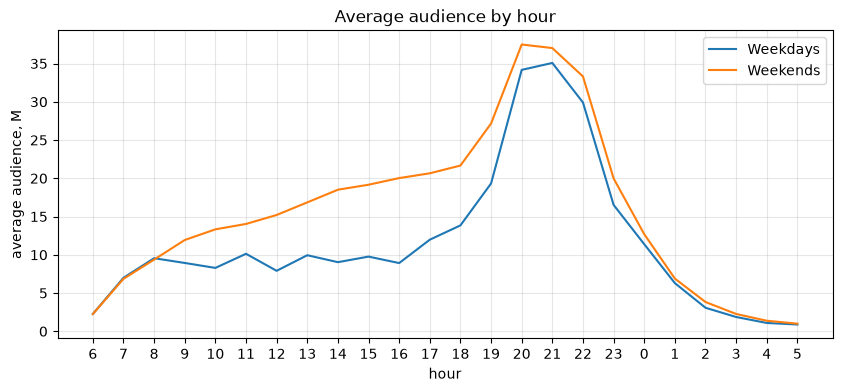

hour         0     1     2     3     4     5     6     7     8      9   ...  \
Weekdays  11.39  6.30  3.08  1.87  1.09  0.89  2.26  6.99  9.55   8.93  ...   
Weekends  12.69  6.89  3.83  2.27  1.38  1.00  2.25  6.86  9.37  11.93  ...   

hour         14     15     16     17     18     19     20     21     22     23  
Weekdays   9.03   9.76   8.92  11.97  13.84  19.32  34.17  35.08  29.91  16.52  
Weekends  18.51  19.16  20.03  20.65  21.66  27.16  37.49  37.02  33.31  19.99  

[2 rows x 24 columns]
Peak hour, weekdays: 21
Peak hour, weekends: 20


In [8]:
# make one row per minute for every session
dur = pv["minutes"].to_numpy()
start_rep = pv.start_ts.to_numpy().repeat(dur)
offset = np.arange(dur.sum()) - np.repeat(np.cumsum(dur) - dur, dur)
minute_ts = pd.Series(start_rep + offset.astype("timedelta64[m]"))

minutes = pd.DataFrame({
    "hour": minute_ts.dt.hour.to_numpy(),
    "bday": broadcast_day(minute_ts).to_numpy(),
    "w": pv.weight.to_numpy().repeat(dur),
})
minutes["weekend"] = minutes.bday.dt.dayofweek >= 5
print("person-minutes:", len(minutes))

days = pd.Series(pd.date_range("2024-10-01", "2024-10-31"))
n_days = (days.dt.dayofweek >= 5).value_counts()
print("weekdays:", n_days[False], " weekend days:", n_days[True])

hourly = minutes.groupby(["weekend", "hour"]).w.sum().div(60).div(n_days, level="weekend").div(1e6)
hourly = hourly.unstack("weekend")
hourly.columns = ["Weekdays", "Weekends"]

# start from 6am like a broadcast day
order = list(range(6, 24)) + list(range(0, 6))
ax = hourly.loc[order].reset_index(drop=True).plot(figsize=(10, 4))
ax.set_xticks(range(24))
ax.set_xticklabels(order)
ax.set_xlabel("hour")
ax.set_ylabel("average audience, M")
ax.set_title("Average audience by hour")
ax.grid(alpha=0.3)
plt.show()

print(hourly.round(2).T)
print("Peak hour, weekdays:", hourly["Weekdays"].idxmax())
print("Peak hour, weekends:", hourly["Weekends"].idxmax())

**Answer:** The peak is in prime time, on weekdays it is 21:00 (about 35.1 M people in an average minute) and on weekends it is 20:00 (about 37.5 M). On weekdays during the day the audience is low, around 8-10 M, and it goes up only after 19:00. On weekends the day is much bigger, almost two times: from 9:00 it grows to about 20 M at 16-18. I think this is because of sport, college football on Saturday and NFL on Sunday. Prime time on weekends is also a bit bigger and starts one hour earlier. At night (2-5) almost nobody watches on both.

## Task 1.3 — Session length

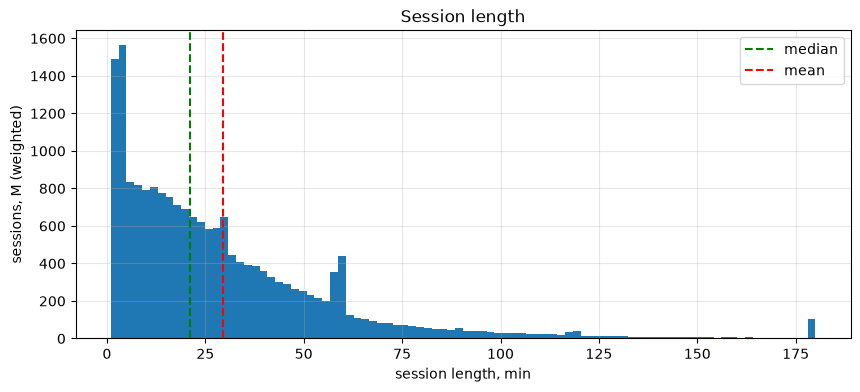

<= 10 min: 0.288
> 120 min: 0.017
Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [9]:
s_len = pv["minutes"].to_numpy()
s_w = pv["weight"].to_numpy()
w_mean = np.average(s_len, weights=s_w)
w_median = weighted_quantile(s_len, s_w, 0.5)

plt.figure(figsize=(10, 4))
plt.hist(np.clip(s_len, 0, 180), bins=90, weights=s_w / 1e6)  # >180 goes to last bin
plt.axvline(w_median, color="green", ls="--", label="median")
plt.axvline(w_mean, color="red", ls="--", label="mean")
plt.xlabel("session length, min")
plt.ylabel("sessions, M (weighted)")
plt.title("Session length")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print("<= 10 min:", round(s_w[s_len <= 10].sum() / s_w.sum(), 3))
print("> 120 min:", round(s_w[s_len > 120].sum() / s_w.sum(), 3))
print("Session length, weighted mean (min):", round(w_mean, 1))
print("Session length, weighted median (min):", round(float(w_median), 1))

**Answer:** Mean is 29.4 min and median is 21 min. The distribution is skewed to the right: a lot of sessions are short (29% are 10 min or less, people switch channels or leave on ads), but there is a long tail of sessions 2-6 hours (sport, news on in background). The mean is sensitive to this tail and the median is not, so the mean is bigger. For a client I would show the median, because it shows a typical session better ("half of sessions are 21 min or less"). The mean is only useful if you want to calculate the total time.

## Task 2 — Program reach curve

In [10]:
dw_by_day = {d: g.set_index("respondent_id")["weight"] for d, g in daily_weights.groupby("broadcast_date")}
type_of = daily_weights.drop_duplicates("respondent_id").set_index("respondent_id")["resp_type"]


# who watched at least 1 minute of the telecast
def telecast_viewers(tc, types):
    s = viewings[(viewings.network_code == tc.network_code) & viewings.resp_type.isin(types)
                 & (viewings.start_ts < tc.end_ts) & (viewings.end_ts > tc.start_ts)]
    overlap = s.end_ts.clip(upper=tc.end_ts) - s.start_ts.clip(lower=tc.start_ts)
    return s.loc[overlap >= pd.Timedelta(minutes=1), "respondent_id"].unique()


def rating(viewer_ids, day, types):
    w = dw_by_day[day]
    w = w[type_of.reindex(w.index).isin(types).to_numpy()]
    return w.reindex(viewer_ids).sum() / w.sum() * 100


# average minute audience, just to compare
def avg_minute_audience(tc, types):
    s = viewings[(viewings.network_code == tc.network_code) & viewings.resp_type.isin(types)
                 & (viewings.start_ts < tc.end_ts) & (viewings.end_ts > tc.start_ts)]
    ov = (s.end_ts.clip(upper=tc.end_ts) - s.start_ts.clip(lower=tc.start_ts)) / pd.Timedelta(minutes=1)
    return (ov * s.weight).sum() / tc.duration_min


def program_telecasts(name, network):
    p = programs[(programs.program_name == name) & (programs.network_code == network)]
    return p.sort_values("start_ts").reset_index(drop=True)

In [11]:
cbs_en = program_telecasts("CBS Evening News", "CBS")
rows = []
person_viewers = []
for tc in cbs_en.itertuples():
    hh = telecast_viewers(tc, ["H"])
    pp = telecast_viewers(tc, PERSON_TYPES)
    person_viewers.append(pp)
    rows.append({
        "date": tc.broadcast_date,
        "HH rating": rating(hh, tc.broadcast_date, ["H"]),
        "P2+ rating": rating(pp, tc.broadcast_date, PERSON_TYPES),
        "Audience (M)": dw_by_day[tc.broadcast_date].reindex(pp).sum() / 1e6,
        "AMA (M)": avg_minute_audience(tc, PERSON_TYPES) / 1e6,
    })
en_table = pd.DataFrame(rows)

# cumulative reach
groups = {
    "P2+": persons.index,
    "A18-34": persons.index[persons.age.between(18, 34)],
    "A18-49": persons.index[persons.age.between(18, 49)],
}
seen = set()
for i, ids in enumerate(person_viewers):
    seen |= set(ids)
    for g, members in groups.items():
        mw = persons.mw.loc[members]
        en_table.loc[i, "reach " + g] = mw[mw.index.isin(seen)].sum() / mw.sum() * 100

en_table.round(2)

,date,HH rating,P2+ rating,Audience (M),AMA (M),reach P2+,reach A18-34,reach A18-49
0,2024-10-01,3.47,1.67,5.28,3.86,1.52,0.08,0.35
1,2024-10-02,3.07,1.48,4.68,3.38,2.37,0.17,0.59
2,2024-10-03,2.99,1.47,4.68,3.46,2.94,0.29,0.80
3,2024-10-04,3.00,1.51,4.81,3.68,3.34,0.44,0.96
4,2024-10-07,3.06,1.52,4.83,3.31,3.84,0.73,1.15
5,2024-10-08,3.17,1.57,4.97,3.61,4.29,0.89,1.31
6,2024-10-09,2.98,1.48,4.70,3.32,4.67,0.89,1.42
7,2024-10-10,3.38,1.62,5.13,3.63,5.17,0.98,1.68
8,2024-10-11,3.09,1.48,4.69,3.46,5.51,1.06,1.92
9,2024-10-14,2.93,1.45,4.59,3.30,5.78,1.24,2.12


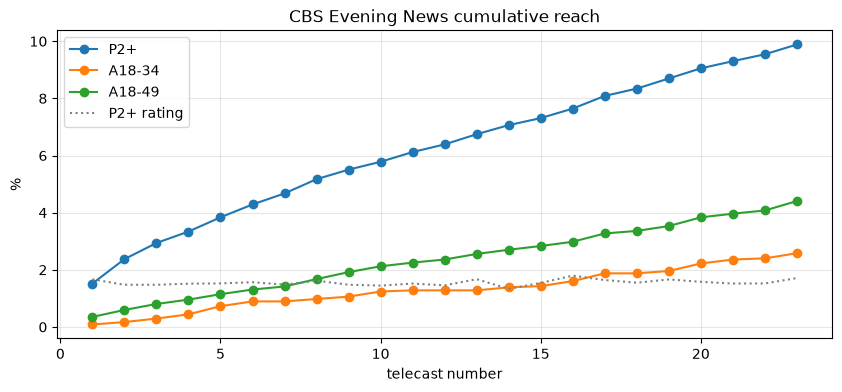

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [12]:
x = range(1, len(en_table) + 1)
plt.figure(figsize=(10, 4))
for g in groups:
    plt.plot(x, en_table["reach " + g], marker="o", label=g)
plt.plot(x, en_table["P2+ rating"], ls=":", color="grey", label="P2+ rating")
plt.xlabel("telecast number")
plt.ylabel("%")
plt.title("CBS Evening News cumulative reach")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print("Telecasts of the program:", len(cbs_en))
print("Average household rating (%):", round(en_table["HH rating"].mean(), 1))
print("Average P2+ rating (%):", round(en_table["P2+ rating"].mean(), 1))
print("Average projected audience (M):", round(en_table["Audience (M)"].mean(), 2))
print("Final reach P2+ (%):", round(en_table["reach P2+"].iloc[-1], 1))
print("Final reach A18-34 (%):", round(en_table["reach A18-34"].iloc[-1], 1))
print("Final reach A18-49 (%):", round(en_table["reach A18-49"].iloc[-1], 1))

**Answer:** The rating of every telecast is almost the same (HH around 3.2%, P2+ around 1.6%, about 4.9 M people), but cumulative reach goes from 1.5% to 9.9% for P2+ after 23 telecasts. Rating is the share of people who watched one telecast, and reach counts unique people who watched at least one of them. Every day not exactly the same people watch, some watch only sometimes, so each new telecast adds new people and reach grows. It grows slower with time, because more and more viewers were already counted before.

Best reach is P2+ (9.9%), then A18-49 (4.4%), and the worst is A18-34 (2.6%). So the program is watched mostly by older people, and it matches what we know: evening news on networks is watched by people 55+ who have a habit, and young people read news online.

Note: Audience (M) here is everyone who watched at least 1 minute (the rule of the lab). Average minute audience (AMA column) is smaller, about 3.5 M.

## Task 3 — Program frequency

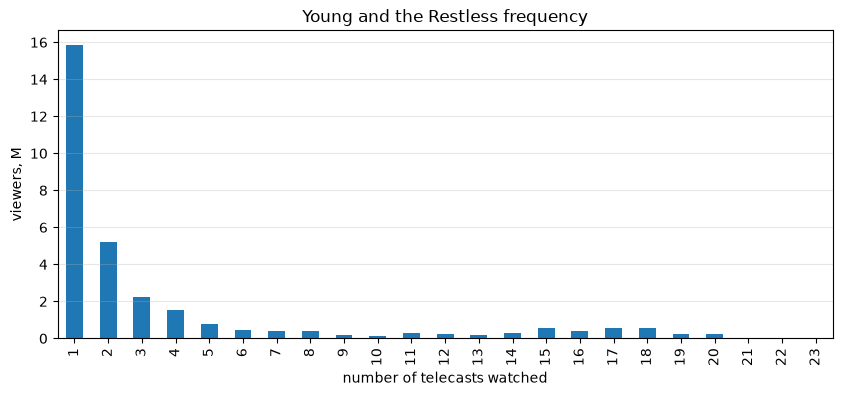

telecasts: 23  p80: 4  loyal viewers share: 0.243
Projected viewers (M): 30.8
Average frequency (weighted): 3.6
Median frequency (weighted): 1.0
Share of views from the most loyal viewers: 0.704


In [13]:
yr = program_telecasts("The Young and the Restless", "CBS")
all_ids = np.concatenate([telecast_viewers(tc, PERSON_TYPES) for tc in yr.itertuples()])
freq = pd.Series(all_ids).value_counts().rename("frequency")
yr_viewers = persons[["mw"]].join(freq, how="inner")
f = yr_viewers.frequency.to_numpy()
w = yr_viewers.mw.to_numpy()

dist = yr_viewers.groupby("frequency").mw.sum().reindex(range(1, len(yr) + 1), fill_value=0) / 1e6
dist.plot.bar(figsize=(10, 4))
plt.xlabel("number of telecasts watched")
plt.ylabel("viewers, M")
plt.title("Young and the Restless frequency")
plt.grid(alpha=0.3, axis="y")
plt.show()

avg_f = np.average(f, weights=w)
med_f = weighted_quantile(f, w, 0.5)
p80 = weighted_quantile(f, w, 0.8)
loyal = f >= p80
loyal_share = (f * w)[loyal].sum() / (f * w).sum()

print("telecasts:", len(yr), " p80:", p80, " loyal viewers share:", round(w[loyal].sum() / w.sum(), 3))
print("Projected viewers (M):", round(w.sum() / 1e6, 2))
print("Average frequency (weighted):", round(avg_f, 1))
print("Median frequency (weighted):", round(float(med_f), 1))
print("Share of views from the most loyal viewers:", round(loyal_share, 3))

**Answer:** The show had 30.80 M viewers in October. Average frequency is 3.6, but median is 1, so more than half of viewers saw only one episode. On the plot there is a big peak at 1 (15.9 M), then it falls fast at 2-5, and then there is a second small group of fans who watch 14-20 episodes out of 23. The 80th percentile is 4, and people with frequency >= 4 are only 24% of viewers but they give 70.4% of all views.

So no, the average is not a fair summary, it "lies". Almost nobody watches 3.6 episodes, there are two different groups (random viewers and loyal fans) and the average just mixes them. It is better to look at the whole distribution, or at least median and share of heavy viewers.

## Task 4 — Networks by age and gender

In [14]:
pv_demo = pv.join(persons[["demo", "age_group"]], on="respondent_id", how="inner")
pv_demo["proj_min"] = pv_demo["minutes"] * pv_demo["weight"]

DEMOS = ["M18-34", "W18-34", "M35-54", "W35-54", "M55+", "W55+"]
by_demo = pv_demo.pivot_table(index="network_code", columns="demo", values="proj_min",
                              aggfunc="sum", fill_value=0) / 1e6

top5 = {}
for d in DEMOS:
    t = by_demo[d].sort_values(ascending=False).head(5)
    top5[d] = [f"{n} ({v:.0f})" for n, v in t.items()]
print("Top 5 networks, projected minutes (M):")
pd.DataFrame(top5, index=range(1, 6))

Top 5 networks, projected minutes (M):


,M18-34,W18-34,M35-54,W35-54,M55+,W55+
1,FOX (4387),FOX (4574),FOX (12805),NBC (11639),CBS (38274),CBS (47120)
2,NBC (3910),NBC (4528),NBC (10987),FOX (11161),NBC (34267),NBC (41392)
3,CBS (3044),ABC (3505),ABC (9037),ABC (9439),FOX (30879),ABC (38840)
4,ABC (3011),CBS (2811),CBS (8134),CBS (8163),ABC (30793),FOX (36915)
5,FX (1474),FX (1383),FX (2371),HGTV (3052),FNC (27904),FNC (31451)


              weighted    raw  raw/weighted
network_code                               
FX               0.266  0.232         0.873
BRAVO            0.148  0.127         0.858
FOX              0.082  0.075         0.918
FOOD             0.078  0.071         0.913
NBC              0.073  0.068         0.932
ABC              0.064  0.060         0.940
HGTV             0.058  0.052         0.896
CBS              0.051  0.050         0.967
HIST             0.048  0.044         0.921
FNC              0.018  0.017         0.956


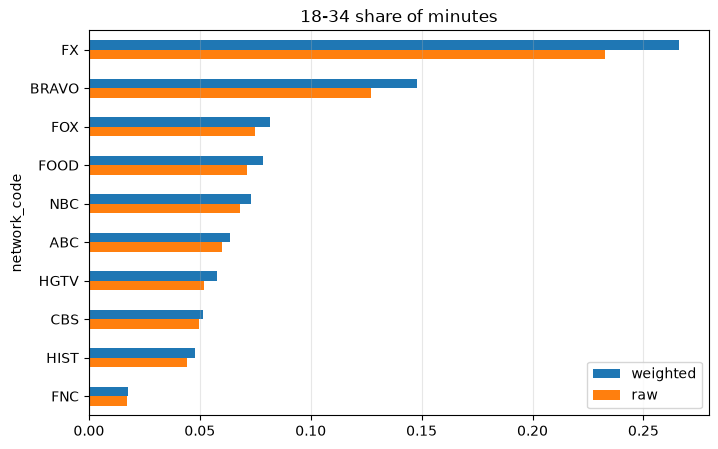

Youngest network: FX
Oldest network: FNC


In [15]:
young = pv_demo[pv_demo.age_group == "18-34"]
share = pd.DataFrame({
    "weighted": young.groupby("network_code").proj_min.sum() / pv_demo.groupby("network_code").proj_min.sum(),
    "raw": young.groupby("network_code")["minutes"].sum() / pv_demo.groupby("network_code")["minutes"].sum(),
}).sort_values("weighted", ascending=False)
share["raw/weighted"] = share["raw"] / share["weighted"]
print(share.round(3))

share[["weighted", "raw"]].plot.barh(figsize=(8, 5))
plt.gca().invert_yaxis()
plt.title("18-34 share of minutes")
plt.grid(alpha=0.3, axis="x")
plt.show()

print("Youngest network:", share["weighted"].idxmax())
print("Oldest network:", share["weighted"].idxmin())

In [16]:
# panel vs universe by age
rep = pd.DataFrame({
    "panel": persons.age_group.value_counts(normalize=True),
    "universe": persons.groupby("age_group").mw.sum() / persons.mw.sum(),
    "avg weight": persons.groupby("age_group").mw.mean().round(0),
})
rep.round(3)

,panel,universe,avg weight
age_group,,,
18-34,0.197,0.229,39810.0
2-17,0.216,0.204,32393.0
35-54,0.331,0.253,26130.0
55+,0.256,0.314,42103.0


**Answer:** The youngest network is FX (26.6% of minutes from 18-34), then Bravo (14.8%). The oldest is Fox News (FNC), only 1.8%.

Without weights the share is lower for all networks (raw/weighted is 0.86-0.97). This is because the panel does not look like the US population. People 18-34 are 19.7% of the panel but 22.9% of the population, so every young person gets a bigger weight (about 39.8k, for 35-54 it is about 26.1k). People 55+ are also under-represented (25.6% vs 31.4%), and 35-54 and kids are over-represented. Young people are hard to get into the panel and keep there. If we show raw numbers to a client, we describe our sample and not the US: FX and Bravo will look about 13-14% older than they are, and GRPs and CPMs for 18-34 and 55+ will be wrong.

**Bonus answer:** Fox News does not have many young viewers, but the ones it has watch live and regularly and don't skip ads, and they are hard to find on entertainment channels. I would sell it as a cheap add-on for extra reach to a main buy on FX or Bravo, not as the main channel for 18-34.